## IA DATASET ANALISIS ##

In [ ]:
import pandas as pd
import numpy as np
%pip install missingno
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Le damos formato y estilo a los graficos del matplolib y seaborn
sns.set_theme(style = "whitegrid", palette = "viridis", font_scale = 1.1)

In [ ]:
#Configuramos para que en todos los graficos aparezcan todas las columnas que solicitamos
pd.set_option('display.max_columns', None)

In [ ]:
# Se carga el dataset en crudo#
df = pd.read_csv('ai_agent_incidents.csv', sep=',', encoding = 'utf-8')
df_copy= df
df

In [ ]:
#Reaslizamos un .shape para ver dimensiones(Rows, Columns)
print(df.shape)

In [ ]:
#Verificam,os primeros datos del dataset con un head
df.head(20)

In [ ]:
#Realizamos un tail para verificar el final del dataset
df.tail(20)

### Nulos y Duplicados ###

Nulos totales en df: 0
Forma: (395, 17)
Duplicados Totales: 0
IDs duplicados: 0


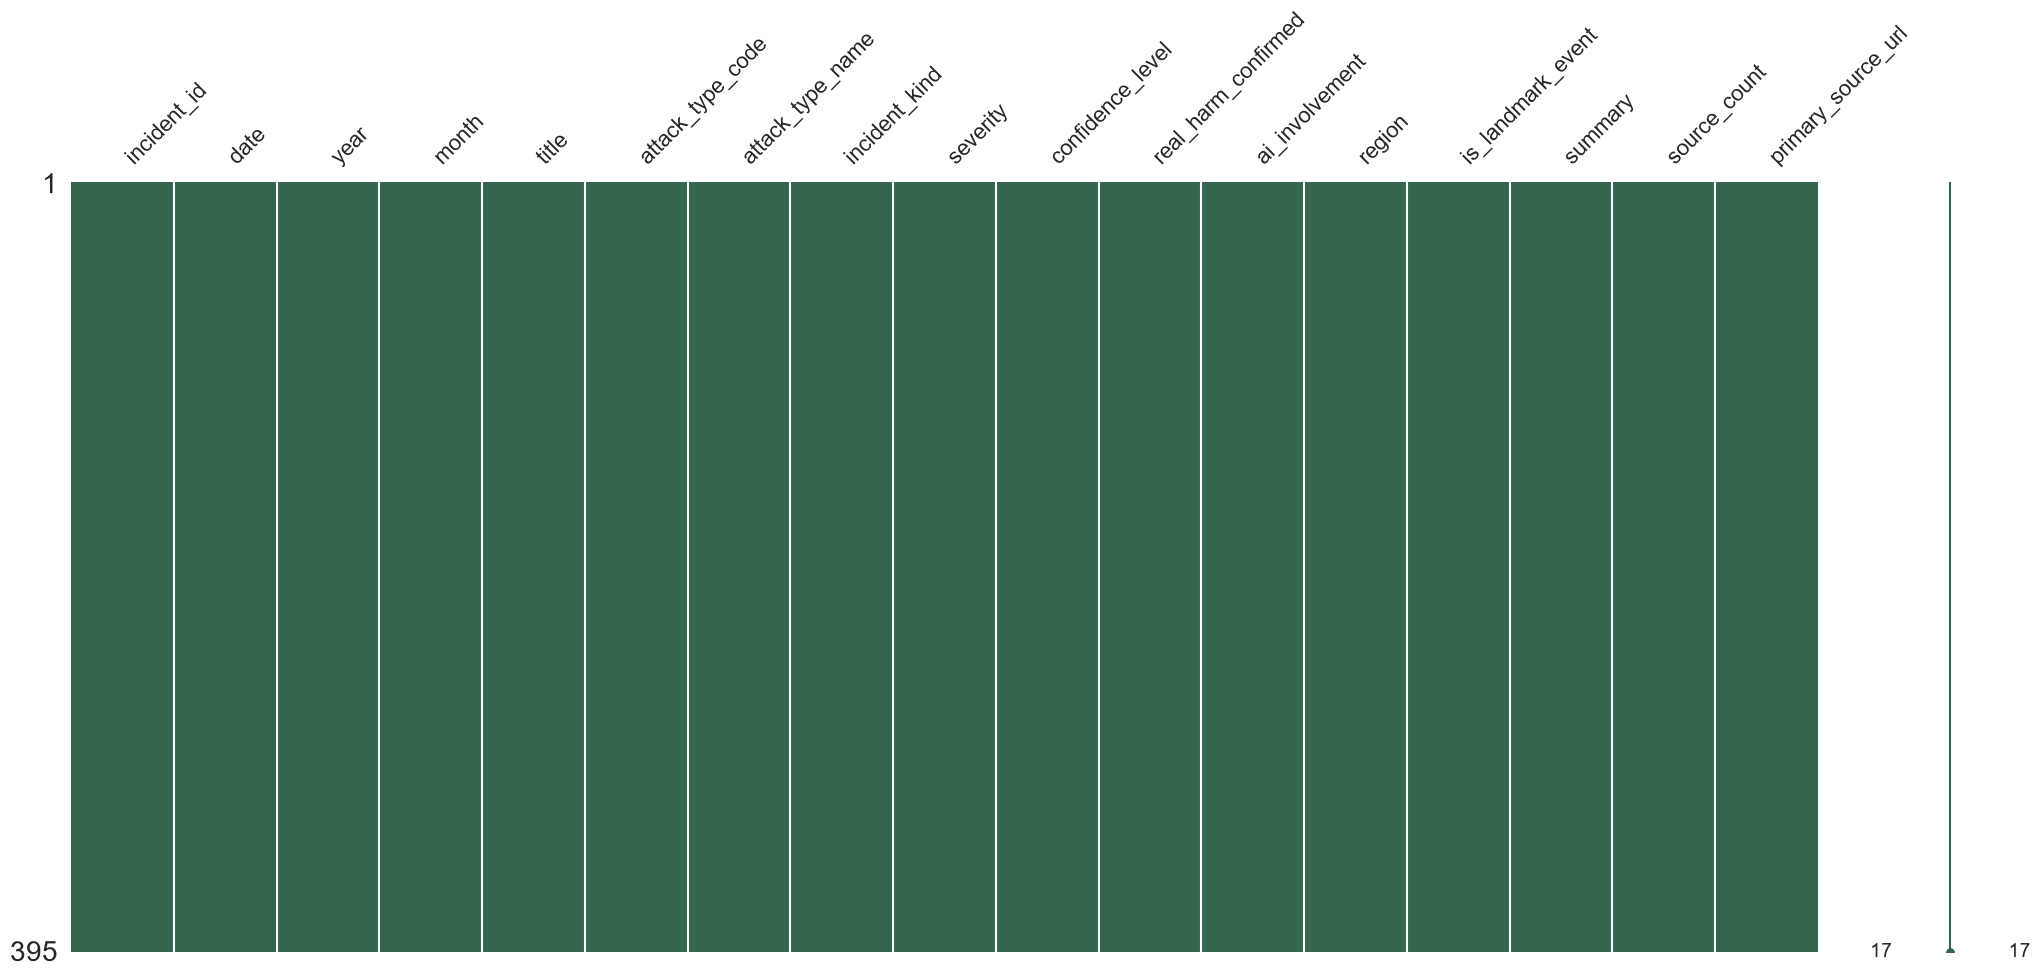

In [11]:
#Vamos a analizar la cantidad de datos nulos y duplicados
print("Nulos totales en df:", df.isnull().sum().sum())
print("Forma:", df.shape) 
print("Duplicados Totales:", df.duplicated().sum())
print("IDs duplicados:", df["incident_id"].duplicated().sum())

msno.matrix(df, color=(0.2, 0.4, 0.3))
plt.show()


#No cuenta con datos duplicados ni con datos nulos

### Tipos y Texto ###

In [12]:
# Vamor a tranformar las variables de texto a tipo fecha para poder trabajar con ellas al igual que las que se necesiten transformar a numero entero
df["date"] = pd.to_datetime(df["date"], errors = "coerce") #Tipo de dato a fecha coerce para que si hay algun error lo transforme a NaT
df["real_harm_confirmed"] = df["real_harm_confirmed"].astype("int") #Convertimos a entero la variable real_harm_confirmed
df["is_landmark_event"] = df["is_landmark_event"].astype("int") #Convertimos a entero la variable is_landmark_event


for c in ["incident_kind", "severity", "confidence_level", "ai_involvement" ]:
    df[c] = df[c].str.strip() .str.lower() #Eliminamos espacios y pasamos a minusculas las variables de texto
for c in ["attack_type_code", "region"]:
    df[c] = df[c].str.strip() .str.upper() #Eliminamos espacios y pasamos a mayusculas las variables de texto

### Tipo de ataque ###

In [13]:
df["attack_list"] = df["attack_type_code"].str.split(";") #Dividimos los tipos de ataque por punto y coma
df["n_attack_types"] = df["attack_list"].str.len() # Creamos una nueva columna con la cantidad de tipos de ataque que tiene cada incidente
atk = df["attack_list"].explode().str.strip()# Explode para separar los tipos de ataque en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
atk_dummies = (pd.crosstab(atk.index, atk).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("atk_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(atk_dummies) # Unimos las variables dummy al DataFrame original

### Regiones ###

In [14]:
df["region_list"] = df["region"].str.split(";") #Dividimos las regiones por punto y coma
df["n_regions"] = df["region_list"].str.len() # Creamos una nueva columna con la cantidad de regiones que tiene cada incidente
reg = df["region_list"].explode().str.strip()# Explode para separar las regiones en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
reg_dummies = (pd.crosstab(reg.index, reg).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("reg_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(reg_dummies) # Unimos las variables dummy al DataFrame original

### Categorias ordenadas a numeros ###

In [15]:
df["severity_ord"] = df["severity"].map( # Creamos una nueva columna con la severidad en orden de importancia
    {"info": 0, "low": 1, "medium": 2, "high": 3, "critical": 4}) # Transforma cada palabra clave en un numero entero
df["confidence_ord"] = df["confidence_level"].map( # Creamos una nueva columna con la confianza en orden de importancia
    {"d": 1, "c": 2, "b": 3, "a": 4})        # supuesto: a = más confiable #Lo mismo solo que dejamos la a como la mayor en este caso
df["ai_confirmed"] = (df["ai_involvement"] == "confirmed").astype(int) #Confirmamos si IA tuvo participacion

### Variables a tiempo ###

In [16]:
df["month_num"] = df["date"].dt.month #Tranformamos el mes en la variable en formato mes
df["quarter"] = df["date"].dt.quarter 
df["dayofweek"] = df["date"].dt.dayofweek
df["days_since_start"] = (df["date"] - df["date"].min()).dt.days #Convertimos el dia de inicio filtrando el minimo en la fecha de cada incidente
df["year_month"] = df["date"].dt.to_period("M").astype(str) #Convertimos en texto el mes de la fecha

### Columnas de referencia y eliminacion ###

In [17]:
referencia = df[["incident_id", "title", "summary", # Pedimos una lista de las columnas y se guardan en una tabla llamada referencias
                 "primary_source_url", "attack_type_name"]].copy() # copy() hace una copia independiente

df = df.drop(columns=["title", "summary", "primary_source_url", #Quita las columnas y devuelve el dataframe sin esas columnas
                      "attack_list", "region_list", "month"])

### Validacion y guardado ###

In [19]:
print("\nForma final:", df.shape) # Nos muestra el dataset final despues de la limpieza
print("Nulos:", df.isnull().sum().sum()) # Imprime la cantidad de los nulos
print("Duplicados:", df.duplicated().sum()) # Imprime la cantidad de duplicados
print(df.dtypes.value_counts()) # Devuelve los tipos de datos y la cantidad de cada uno

df.to_csv("incidentes_limpio.csv", index=False) #Convierte el df nuevo en csv
referencia.to_csv("incidentes_referencia.csv", index=False) #Nombre del csv original 


Forma final: (395, 48)
Nulos: 0
Duplicados: 0
int64             35
str                9
int32              3
datetime64[us]     1
Name: count, dtype: int64
